# Anomaly Detection — Guided Examples

This notebook demonstrates outlier detection and novelty detection using synthetic data. It compares Isolation Forest, Local Outlier Factor, and One-Class SVM, then evaluates results using synthetic labels.

**Important:** anomaly scores are not confirmed labels. Use validation data to select thresholds and reserve the final test set for evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    roc_auc_score, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

## 1. Generate a dataset with known anomalies
We create clustered normal observations and inject points outside the main clusters. The labels are for evaluation only.

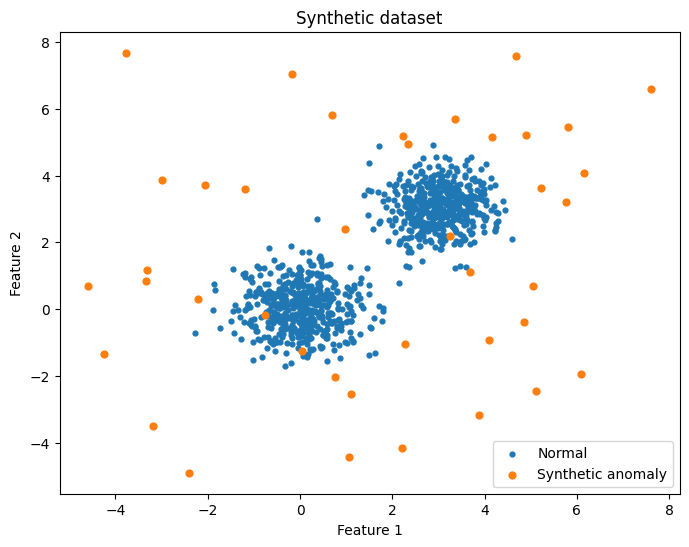

Rows: 1040 | anomaly prevalence: 0.0385


In [2]:
rng = np.random.default_rng(RANDOM_STATE)
X_normal, _ = make_blobs(
    n_samples=1000, centers=[(0, 0), (3, 3)],
    cluster_std=[0.7, 0.6], random_state=RANDOM_STATE
)
X_anomaly = rng.uniform(low=-5, high=8, size=(40, 2))
X = np.vstack([X_normal, X_anomaly])
y_true = np.r_[np.zeros(len(X_normal), dtype=int),
               np.ones(len(X_anomaly), dtype=int)]

plt.figure(figsize=(8, 6))
plt.scatter(X[y_true == 0, 0], X[y_true == 0, 1], s=12, label="Normal")
plt.scatter(X[y_true == 1, 0], X[y_true == 1, 1], s=24, label="Synthetic anomaly")
plt.legend()
plt.title("Synthetic dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()
print("Rows:", len(X), "| anomaly prevalence:", round(y_true.mean(), 4))

## 2. Outlier detection with Isolation Forest
Scikit-learn predicts `1` for inliers and `-1` for outliers. Here, negating `decision_function` creates a score where larger means more anomalous.

Precision: 0.769
Recall: 0.833
F1: 0.8
Average precision: 0.858
ROC-AUC: 0.959


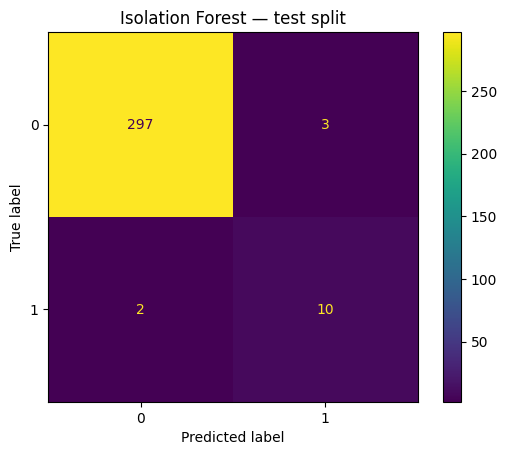

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_true, test_size=0.30, stratify=y_true, random_state=RANDOM_STATE
)

iso = IsolationForest(n_estimators=200, contamination=0.04, random_state=RANDOM_STATE)
iso.fit(X_train)
test_labels = iso.predict(X_test)
test_pred = (test_labels == -1).astype(int)
test_score = -iso.decision_function(X_test)

print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 3))
print("F1:", round(f1_score(y_test, test_pred, zero_division=0), 3))
print("Average precision:", round(average_precision_score(y_test, test_score), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_score), 3))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title("Isolation Forest — test split")
plt.show()

## 3. Local Outlier Factor for outlier detection
`fit_predict` is the usual interface for finding outliers in the dataset used for fitting. `negative_outlier_factor_` is more negative for more abnormal observations, so we negate it for ranking.

In [4]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.04)
lof_labels = lof.fit_predict(X_train)
train_pred = (lof_labels == -1).astype(int)
train_score = -lof.negative_outlier_factor_
print("Training flagged:", train_pred.sum())
print("Training precision:", round(precision_score(y_train, train_pred, zero_division=0), 3))
print("Training recall:", round(recall_score(y_train, train_pred, zero_division=0), 3))
print("Training AP:", round(average_precision_score(y_train, train_score), 3))

Training flagged: 30
Training precision: 0.833
Training recall: 0.893
Training AP: 0.934


## 4. Novelty detection with LOF
For novelty detection, fit on normal examples only and use `novelty=True`. Use `predict` on unseen data—not the training observations.

In [5]:
X_normal_train = X_train[y_train == 0]
lof_novelty = make_pipeline(
    StandardScaler(),
    LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.04)
)
lof_novelty.fit(X_normal_train)
novelty_labels = lof_novelty.predict(X_test)
novelty_pred = (novelty_labels == -1).astype(int)
print("Precision:", round(precision_score(y_test, novelty_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, novelty_pred, zero_division=0), 3))

Precision: 0.345
Recall: 0.833


## 5. One-Class SVM
One-Class SVM is sensitive to feature scale. This pipeline fits a scaler on normal training observations and then learns a boundary around them.

In [6]:
ocsvm = make_pipeline(
    StandardScaler(),
    OneClassSVM(kernel="rbf", nu=0.04, gamma="scale")
)
ocsvm.fit(X_normal_train)
svm_labels = ocsvm.predict(X_test)
svm_pred = (svm_labels == -1).astype(int)
svm_score = -ocsvm.decision_function(X_test)
print("Precision:", round(precision_score(y_test, svm_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, svm_pred, zero_division=0), 3))
print("F1:", round(f1_score(y_test, svm_pred, zero_division=0), 3))
print("AP:", round(average_precision_score(y_test, svm_score), 3))

Precision: 0.417
Recall: 0.833
F1: 0.556
AP: 0.85


## 6. Compare algorithms
The detectors make different assumptions. Compare both thresholded classification metrics and ranking quality where a score is available.

In [7]:
results = pd.DataFrame([
    {
        "model": "Isolation Forest",
        "precision": precision_score(y_test, test_pred, zero_division=0),
        "recall": recall_score(y_test, test_pred, zero_division=0),
        "f1": f1_score(y_test, test_pred, zero_division=0),
        "average_precision": average_precision_score(y_test, test_score),
    },
    {
        "model": "LOF novelty",
        "precision": precision_score(y_test, novelty_pred, zero_division=0),
        "recall": recall_score(y_test, novelty_pred, zero_division=0),
        "f1": f1_score(y_test, novelty_pred, zero_division=0),
        "average_precision": np.nan,
    },
    {
        "model": "One-Class SVM",
        "precision": precision_score(y_test, svm_pred, zero_division=0),
        "recall": recall_score(y_test, svm_pred, zero_division=0),
        "f1": f1_score(y_test, svm_pred, zero_division=0),
        "average_precision": average_precision_score(y_test, svm_score),
    },
]).set_index("model")
display(results.round(3))

,precision,recall,f1,average_precision
model,,,,
Isolation Forest,0.769,0.833,0.800,0.858
LOF novelty,0.345,0.833,0.488,NaN
One-Class SVM,0.417,0.833,0.556,0.850


## 7. Visualize Isolation Forest alerts
The chart below shows held-out observations and marks the detector's predicted anomalies. The synthetic labels remain separate so false positives and false negatives can be inspected.

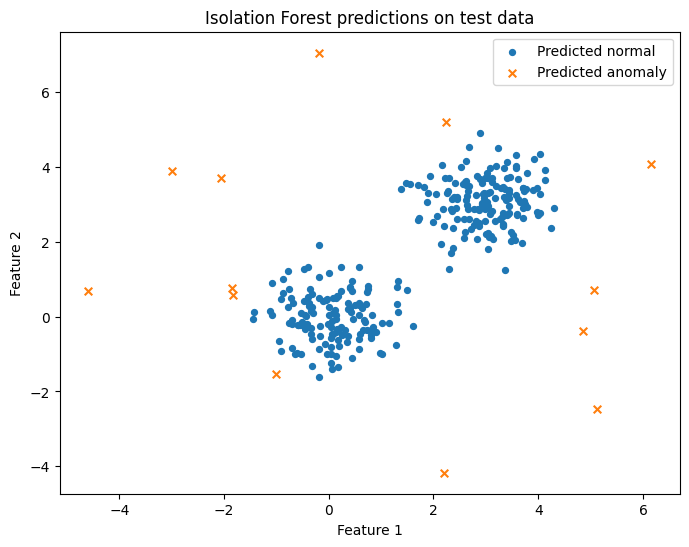

False positives: 3
False negatives: 2


In [8]:
plt.figure(figsize=(8, 6))
plt.scatter(X_test[test_pred == 0, 0], X_test[test_pred == 0, 1],
            s=18, label="Predicted normal")
plt.scatter(X_test[test_pred == 1, 0], X_test[test_pred == 1, 1],
            s=30, label="Predicted anomaly", marker="x")
plt.legend()
plt.title("Isolation Forest predictions on test data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

false_positives = np.flatnonzero((test_pred == 1) & (y_test == 0))
false_negatives = np.flatnonzero((test_pred == 0) & (y_test == 1))
print("False positives:", len(false_positives))
print("False negatives:", len(false_negatives))

## 8. Reflection
1. Which algorithm produced the best precision/recall trade-off on this dataset?
2. How did scaling affect One-Class SVM and LOF?
3. What would change if normal training data were contaminated?
4. How would you choose an alert threshold when only 20 alerts per day can be reviewed?
5. What monitoring and analyst feedback would you use in production?

**Takeaway:** anomaly detection prioritizes unusual observations. Validate alerts with context and evidence before treating them as errors, fraud, or security incidents.